<a href="https://colab.research.google.com/github/Deveshjd/ML-Notebooks/blob/main/OnlineRetailE2E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [79]:
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

In [3]:
data = pd.read_excel("/content/online_retail_II.xlsx")

In [4]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
data.shape

(525461, 8)

In [7]:
data.isnull().sum()

,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


In [19]:
data[data["Customer ID"].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
525231,538159,21324,NaN,-18,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525232,538158,20892,NaN,-32,2010-12-09 17:17:00,0.00,NaN,United Kingdom
525233,538160,20956,NaN,288,2010-12-09 17:18:00,0.00,NaN,United Kingdom
525234,538161,46000S,Dotcom sales,-100,2010-12-09 17:25:00,0.00,NaN,United Kingdom


In [18]:
data[data["Description"].isnull()]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
524730,538141,22218,NaN,2,2010-12-09 15:58:00,0.0,NaN,United Kingdom
524731,538143,84534B,NaN,1,2010-12-09 15:58:00,0.0,NaN,United Kingdom
525231,538159,21324,NaN,-18,2010-12-09 17:17:00,0.0,NaN,United Kingdom
525232,538158,20892,NaN,-32,2010-12-09 17:17:00,0.0,NaN,United Kingdom


In [10]:
data.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
525456,False
525457,False
525458,False
525459,False


In [11]:
data.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [20]:
data.nunique()

,0
Invoice,28816
StockCode,4632
Description,4681
Quantity,825
InvoiceDate,25296
Price,1606
Customer ID,4383
Country,40


In [24]:
print("Original shape:", data.shape)

print("\nMissing values:")
print(data.isna().sum())

print("\nCustomer ID missing percentage:")
print(data["Customer ID"].isna().mean() * 100)

print("\nDescription missing percentage:")
print(data["Description"].isna().mean() * 100)

print("\nRows missing either field:")
print(data[["Customer ID", "Description"]].isna().any(axis=1).sum())

Original shape: (525461, 8)

Missing values:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
dtype: int64

Customer ID missing percentage:
20.53948818275762

Description missing percentage:
0.5572249891048051

Rows missing either field:
107927


In [25]:
# Preserve the original data
df_raw = data.copy()

# General sales and product analysis
sales_df = df_raw.dropna(subset=["Description"]).copy()

# Customer-level analysis and segmentation
customer_df = sales_df.dropna(subset=["Customer ID"]).copy()

print("Raw data:", df_raw.shape)
print("Sales analysis:", sales_df.shape)
print("Customer analysis:", customer_df.shape)

Raw data: (525461, 8)
Sales analysis: (522533, 8)
Customer analysis: (417534, 8)


In [41]:
print(df_raw.dtypes)

# checking negative and zero qty
print("\nNegative Qantity : ",(df_raw["Quantity"] < 0).sum())
print("Zero Quantity : ",(df_raw["Quantity"]==0).sum())

# checking negative and zero prices
print("\nNegative Prices : ",(df_raw["Price"] < 0).sum())
print("Zero Prices : ",(df_raw["Price"]==0).sum())

# inspecting invoice indentifiers:
print("\nInvoice Starting with C : ", df_raw["Invoice"].astype(str).str.startswith("C").sum())
print("\nInvoice Starting with A : ", df_raw["Invoice"].astype(str).str.startswith("A").sum())

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

Negative Qantity :  12326
Zero Quantity :  0

Negative Prices :  3
Zero Prices :  3687

Invoice Starting with C :  10206

Invoice Starting with A :  3


In [58]:
# inspecting -ve quantity:

print("Negative Qty")
display(
    df_raw[df_raw["Quantity"]<0][
    ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Price", "Customer ID"]].head(10)
)


# Inspecting -ve price txn:
print("\nNegative Price")
display(
    df_raw[df_raw["Price"]<0]
)

# Inspecting zero price txn:
print("\nZero Price")
display(
    df_raw[df_raw["Price"]==0][
    ["Invoice", "StockCode", "Description",
         "Quantity", "Price"]].head(10)
)


# check overlap between cancellations and negative transactions
is_cancelled = df_raw["Invoice"].astype(str).str.startswith("C")
is_negative_qty = df_raw["Quantity"]<0


print("cancellation invoice : ", is_cancelled.sum())
print("negative qty invoice : ", is_negative_qty.sum())
print("Both conditions : ", (is_cancelled & is_negative_qty).sum())
print("Negative quantity without C invoice:",
      (~is_cancelled & is_negative_qty).sum())

Negative Qty


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0



Negative Price


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom



Zero Price


,Invoice,StockCode,Description,Quantity,Price
263,489464,21733,85123a mixed,-96,0.0
283,489463,71477,short,-240,0.0
284,489467,85123A,21733 mixed,-192,0.0
470,489521,21646,NaN,-50,0.0
3114,489655,20683,NaN,-44,0.0
3161,489659,21350,NaN,230,0.0
3162,489660,35956,lost,-1043,0.0
3168,489663,35605A,damages,-117,0.0
3731,489781,84292,NaN,17,0.0
4296,489806,18010,NaN,-770,0.0


cancellation invoice :  10206
negative qty invoice :  12326
Both conditions :  10205
Negative quantity without C invoice: 2121


In [73]:
# start with records that have known customer ID
customer_df = sales_df.dropna(subset=["Customer ID"]).copy()

# keeping only complete purchases
customer_df = customer_df[
    (customer_df["Price"]>0) &
    (customer_df["Quantity"]>0) &
    (customer_df["Invoice"].astype(str).str.startswith("C")==False)
].copy()

# calculating the txn revenue
customer_df["Revenue"] = customer_df["Quantity"] * customer_df["Price"]

print("Clean customer dataset:", customer_df.shape)
print("Remaining missing values:")
print(customer_df.isnull().sum())

Clean customer dataset: (407664, 9)
Remaining missing values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
Revenue        0
dtype: int64


In [78]:
# dataset overview
print("Shape:", customer_df.shape)
print("Date range")
print(customer_df["InvoiceDate"].min())
print(customer_df["InvoiceDate"].max())

# Basic statistics
display(
    customer_df[[
        "Quantity", "Price", "Revenue"
    ]].describe()
)

# Number of unique entities
print("Unique customers:", customer_df["Customer ID"].nunique())
print("Unique invoices:", customer_df["Invoice"].nunique())
print("Unique products:", customer_df["StockCode"].nunique())
print("Countries:", customer_df["Country"].nunique())

Shape: (407664, 9)
Date range
2009-12-01 07:45:00
2010-12-09 20:01:00


,Quantity,Price,Revenue
count,407664.000000,407664.000000,407664.000000
mean,13.585585,3.294438,21.664909
std,96.840747,34.757965,77.150058
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,5.000000,1.950000,11.900000
75%,12.000000,3.750000,19.500000
max,19152.000000,10953.500000,15818.400000


Unique customers: 4312
Unique invoices: 19213
Unique products: 4017
Countries: 37


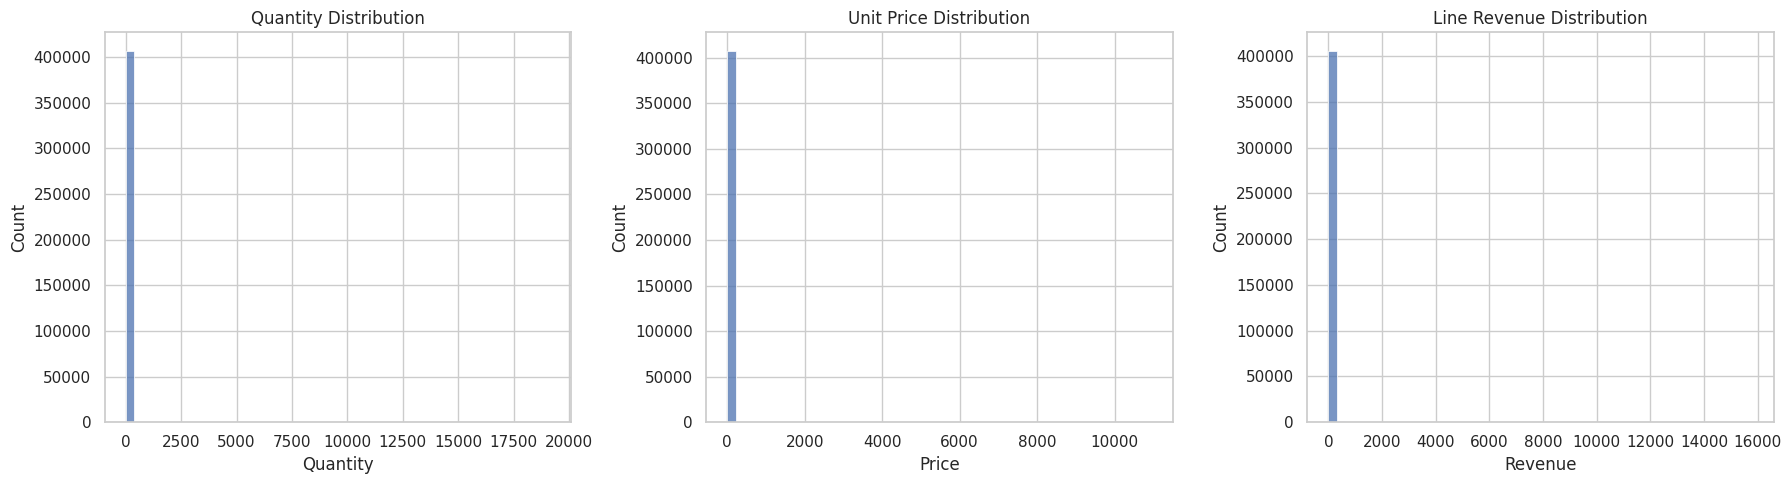

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=customer_df, x="Quantity", bins=50, ax=axes[0])
axes[0].set_title("Quantity Distribution")

sns.histplot(data=customer_df, x="Price", bins=50, ax=axes[1])
axes[1].set_title("Unit Price Distribution")

sns.histplot(data=customer_df, x="Revenue", bins=50, ax=axes[2])
axes[2].set_title("Line Revenue Distribution")

plt.tight_layout()
plt.show()

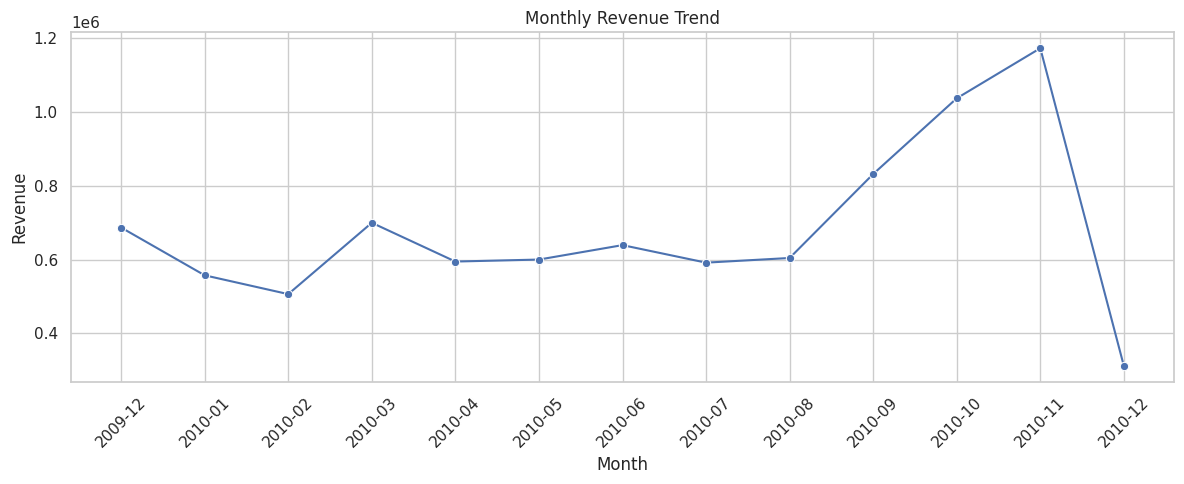

In [81]:

# Extract month from each transaction date
customer_df["Month"] = (
    customer_df["InvoiceDate"].dt.to_period("M").astype(str)
)

# Aggregate revenue by month
monthly_revenue = (
    customer_df.groupby("Month")["Revenue"]
    .sum()
    .sort_index()
)

# Plot
plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_revenue.index, y=monthly_revenue.values, marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


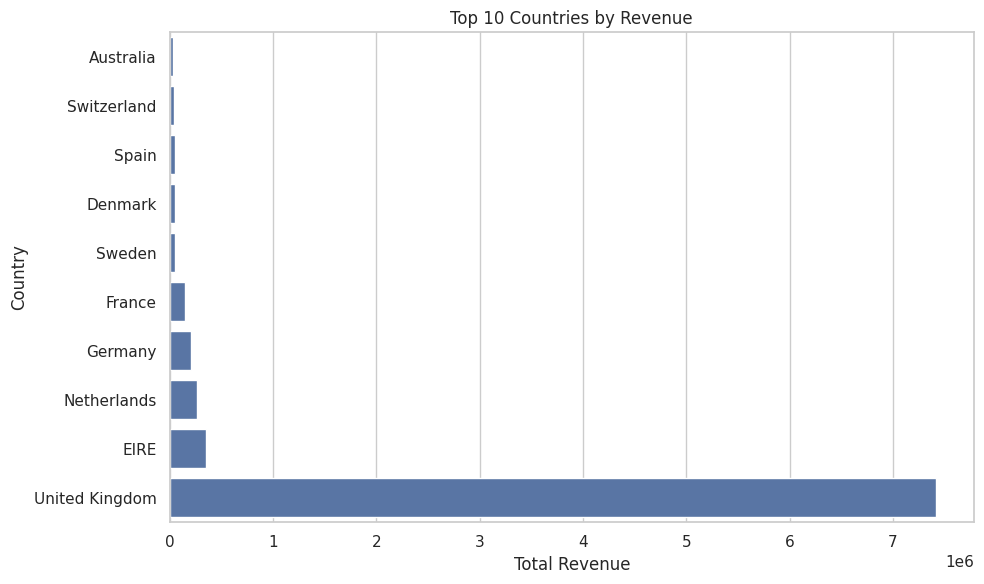

In [82]:
# Find top 10 countries by revenue

countries_revenue = (
    customer_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Plot
plt.figure(figsize = (10,6))
sns.barplot(x=countries_revenue.values, y=countries_revenue.index)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

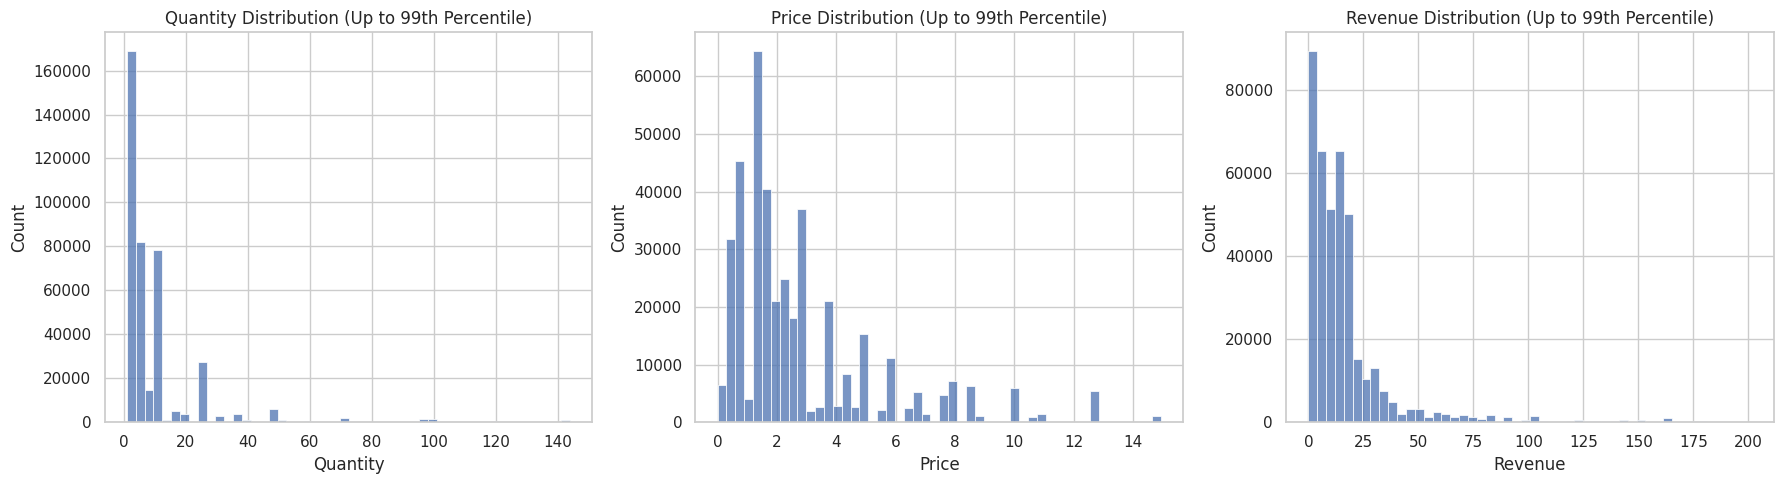

In [83]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

columns = ["Quantity", "Price", "Revenue"]

for ax, col in zip(axes, columns):
    upper_limit = customer_df[col].quantile(0.99)

    sns.histplot(
        data=customer_df[customer_df[col] <= upper_limit],
        x=col,
        bins=50,
        ax=ax
    )

    ax.set_title(f"{col} Distribution (Up to 99th Percentile)")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()


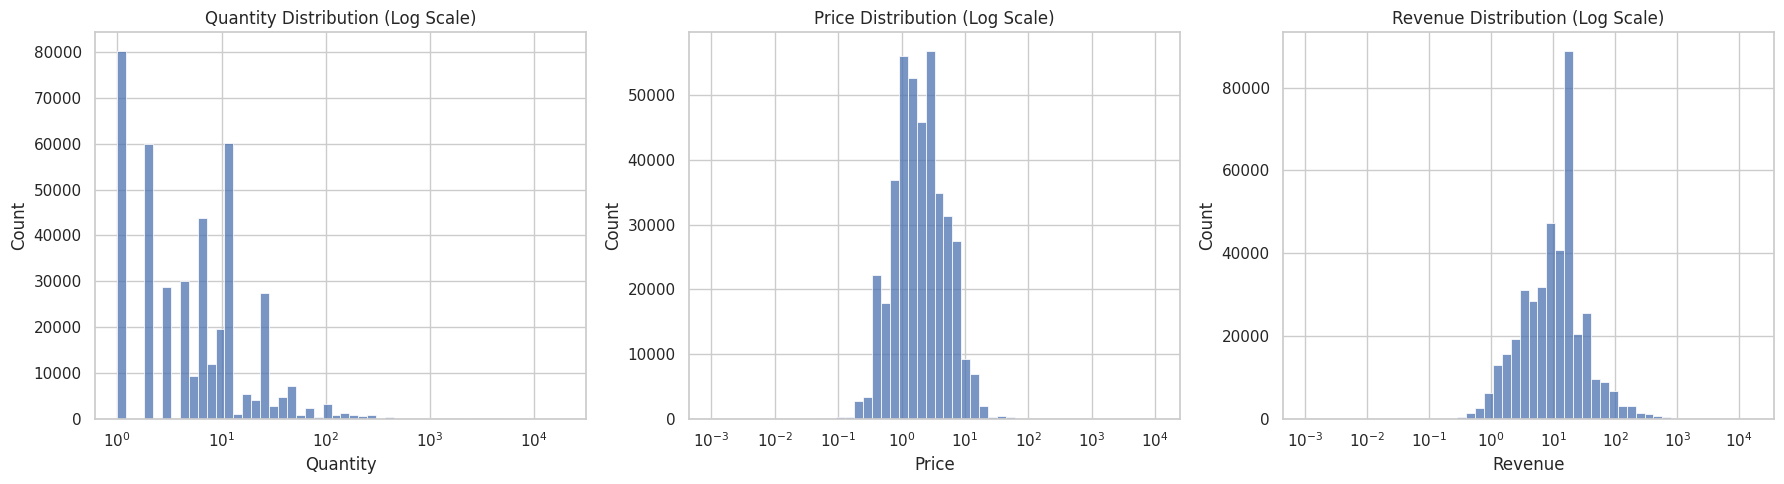

In [84]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, ["Quantity", "Price", "Revenue"]):
    sns.histplot(
        x=customer_df[col],
        bins=50,
        log_scale=True,
        ax=ax
    )
    ax.set_title(f"{col} Distribution (Log Scale)")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()
